# Predicting Survival on the Titanic: a Machine Learning Model

This project is part of Kaggle's "Titanic - Machine Learning from Disaster" competition. As a beginner in machine learning, my goal was not to compete but to try taking on this project on my own, and practicing my skills. Credit for the idea and data goes to Kaggle. 

## Introduction

In this project, I build a machine learning model to predict survival status in the Titanic disaster (i.e. whether a given passenger would have survived or not). The data used was downloaded from Kaggle and already divided into training and test parts; the training.csv data contains passenger information and a column indicating survival, whereas the test.csv contains passenger data without the survival column, to use to test the accuracy of one's model. Therefore, below, I use the training.csv file to build my model in this project. The data is not completely clean: some passengers have no recorded age (177), cabin (687) or port of embarkation (2). I point out below how I deal with each of these when they come up.

---

## Step 1: Loading and exploring the data
I start by loading and inspecting the training dataset ('training.csv'), in order to get a general idea of what I'll be working with.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
#Loading the training data
training_df = pd.read_csv("data/titanic/train.csv")
training_df.head()

#Checking the shape of the dataset
print("Shape of the dataset:", training_df.shape)

#Checking the column names and corresponding data types
print("\nColumn Info")
print(training_df.info())

Shape of the dataset: (891, 12)

Column Info
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB
None


Now I know that I have a training data frame of 12 features and 891 observations, which contains different data types.

Next, I will try to answer some basic questions about the data that I have. For instance, what's the distribution in categorical features like survival status, sex and class? 

### Finding patterns with categorical features

In [3]:
#survival stats
print("Survival distribution")
print(training_df['Survived'].value_counts())

#gender stats
print("\nGender distribution")
print(training_df['Sex'].value_counts())

#class stats
print("\nClass distribution")
print(training_df['Pclass'].value_counts())

Survival distribution
Survived
0    549
1    342
Name: count, dtype: int64

Gender distribution
Sex
male      577
female    314
Name: count, dtype: int64

Class distribution
Pclass
3    491
1    216
2    184
Name: count, dtype: int64


There seems to be more males than females, more third class passengers than second and first combined, and more than half of the passengers did NOT survive. Gender and class might be important predictors in survival which I will focus on while building the model; of course, this also makes sense based on what we know about the Titanic disaster and their methods of evacuation (i.e. "women and children first"). 

Below I do some data visualization to look for connections between these features, to understand the dataset and to uncover as many patterns as I can that will help me in my later steps. 

To generate these plots I used pandas' crosstab() function which performs cross-tabulation, which creates a new data frame showing the frequencies of observations focused on just two columns of your choosing. For instance, below I wanted to plot gender vs. survival, and the data frame created by a cross-tabulation step would be a table that has values for survival on the horizontal axis (0 or 1), and values for gender on the vertical axis (M or F), the four slots of the table would include the frequencies of each "group" (men survived, men didn't survive, female survived, female didn't survive). Once I have such a data frame, I feel less overwhelmed by the data and can easily visualize what I am interested in. 

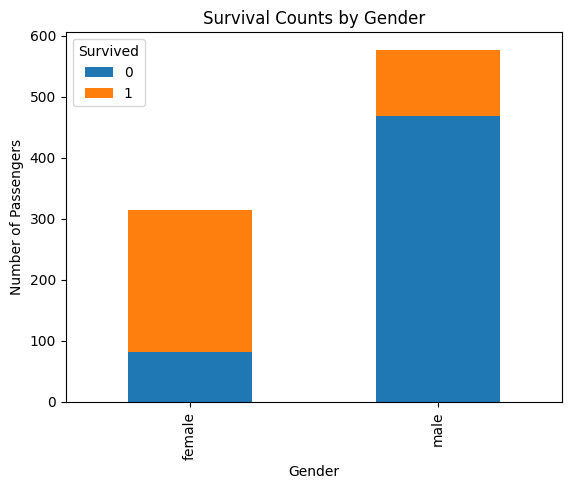

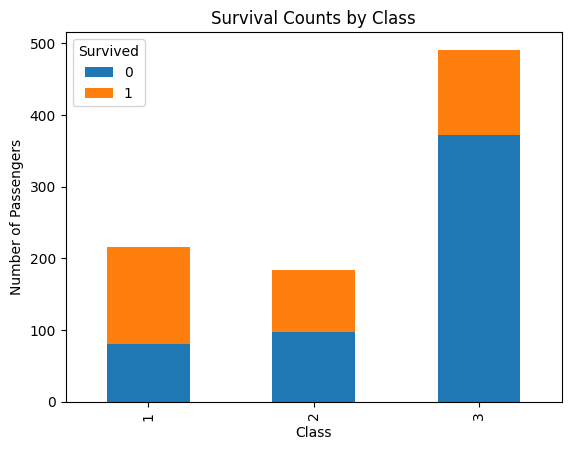

In [4]:
#Cross-tabulation steps
survival_by_gender = pd.crosstab(training_df['Sex'], training_df['Survived'])
survival_by_class = pd.crosstab(training_df['Pclass'], training_df['Survived'])

#Bar plot for gender vs survival
ax = survival_by_gender.plot(kind="bar", stacked=True)
ax.set_title('Survival Counts by Gender')
ax.set_xlabel('Gender')
ax.set_ylabel('Number of Passengers')
plt.show()

#Bar plot for class vs survival
axi = survival_by_class.plot(kind="bar", stacked=True)
axi.set_title('Survival Counts by Class')
axi.set_xlabel('Class')
axi.set_ylabel('Number of Passengers')
plt.show()

From these plots I can once again see that while the majority of females on board survived, the majority of males did not. Similarly, while survival was close to half of first and second class passengers, only a minority of third class passengers survived.

### Finding patterns with non-categorical data

The data above was categorical (male/female, 1/0, 1/2/3 etc), so I was able to use cross-tabulation to inspect frequencies of each combination of 'categories'. Now, I will plot data that is not categorial, but rather continuous, like age. The data frame resulting from cross-tabulation of age vs. survival would be very large and probably a complete mess to try to read.

I am interested in how survival status is distributed in features like age or fare. 

First, I want to plot age vs survival. I want a plot that gives me a good idea of the overall age distribution and also shows survival status by age (for instance, did older people die more than younger people? etc). I decided to use a histogram with the bars filled to represent survival.

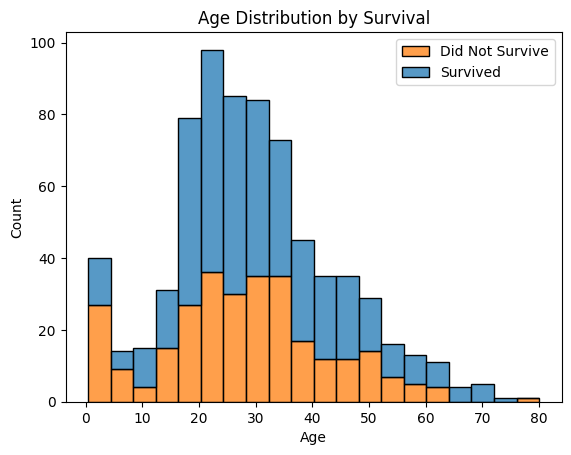

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(data=training_df, x='Age', hue='Survived', bins=20, multiple='stack')
plt.title('Age Distribution by Survival')
plt.xlabel('Age')
plt.ylabel('Count')
plt.legend(labels=['Did Not Survive', 'Survived'])
plt.show()

The age distribution seems balanced enough; most passengers are between 20-40 years old, the younger passengers (the children) probably accompanying their parents in this age group or slightly above. The oldest passengers could also be accompanying their younger family members or traveling alone. Later on, I can check this by inspecting the 'SibSp' feature, which contains information about the siblings and spouses each passenger had on board. 

What about fare? Does the amount of money passengers paid for their tickets correlate in any way with their survival?

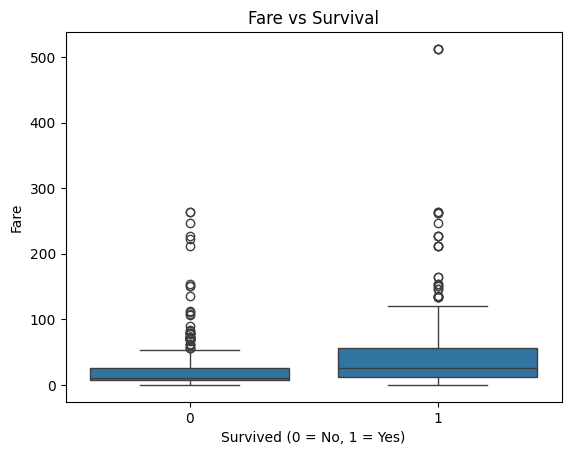

In [6]:
sns.boxplot(data=training_df, x='Survived', y='Fare')
plt.title('Fare vs Survival')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Fare')
plt.show()

The boxplot is nice to see the outliers and spread of the fare data. I can see that the passengers who survived paid more for their tickets on average, which makes sense because fare would likely correlate with class, which we already believe to be important in survival outcome.

Now that I have loaded, explored and visualized the training data, I have a much better understanding of the features included, what they represent, what kind of values they hold, and how they correlate with survival. Now ready to move on to the next step towards building a machine learning model! 

## Step 2: Converting categorial columns into numeric

My next step is to convert categorial columns into numerical ones (because the machine learning models I use downstream cannot handle strings like "female").

To do this, I will use the get_dummies() function from pandas. This function takes as parameters a dataset and its column names of interest, and then converts the values of these columns into "dummy variables"; in regression analysis, dummy variables take a binary value (so, 1 or 0) to represent two categories that are mutually exclusive. For instance, the binary values could represent male/female, yes/no, survived/did not survive, etc. While the data itself remains the same, it is no longer represented by a string of text but rather a simple 1 or 0 that acts as a secret code for the model to understand! 

I start by reminding myself of my dataset and which features have categorial data that might need converting. 

In [7]:
training_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Few columns store categorical values; these are sex, cabin and embarked. For now, I will ignore the cabin information because it has many missing (NaN) values and a complicated naming method including a combination of letters and numbers. Overall, this seems like a messy column, and in this step I just want to focus on "one-hot encoding" simple columns with only a few categories: sex (2 categories) and embarked (3 ports: C, Q and S).

Two passengers have no recorded port, so I give "unknown" its own column (dummy_na=True); otherwise these two passengers would quietly end up looking like they boarded at port C. I also drop PassengerId, since it is just a row number and has nothing to do with survival. The missing ages I leave as they are for now, because the scikit-learn tree models I use below can handle missing values on their own.

I will make sure to copy my training data in an object so that I will be able to return to the original if needed. Then, I can start converting my categories into dummy variables in this copy... 

In [8]:
#copy training data in df
df = training_df.copy()

#convert to dummy variables using the copy df
#(dummy_na=True gives the 2 passengers with no recorded port their own column, instead of silently counting them as 'C')
df = pd.get_dummies(df, columns = ['Sex'], drop_first=True)
df = pd.get_dummies(df, columns = ['Embarked'], drop_first=True, dummy_na=True)

#get rid of unwanted (for now) columns; PassengerId is just a row number, so it can't tell the model anything about survival
df = df.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis = 1)

#checking the dataset now
df.head()

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S,Embarked_nan
0,0,3,22.0,1,0,7.2500,True,False,True,False
1,1,1,38.0,1,0,71.2833,False,False,False,False
2,1,3,26.0,0,0,7.9250,False,False,True,False
3,1,1,35.0,1,0,53.1000,False,False,True,False
4,0,3,35.0,0,0,8.0500,True,False,True,False


Instead of 0/1 values I now have True/False values in my data, which are Boolean values where True=1='present' and False=0='false'. Since Python will likely treat these the same as 1/0 values when needed, I will leave them as they are. If I have any trouble down the line, I can convert them using the call: df.astype(int).

Below are some notes about the code above, for my future self:
#### why use drop_first=True ?
The way get_dummies() works is this: when I have a column 'sex' that contains rows with data like 'female' or 'male' in each, the get_dummies call creates two columns out of it-- a male column and a female column, each of which contains 1 or 0 (or True or False) to represent whether the passenger is male or female. If the male column of one row has value 1, the female column of the same row must certainly have value 0, since these are mutually exclusive. Therefore, we actually have two columns for no reason at all, information in one column alone would be sufficient for us. When we include this drop statement, it drops one of these columns that had been created in the process. This is why my new data frame now contains the column Sex_male instead of the previous Sex column!

#### why specify axis=1 in df.drop() ?
It took me quite some time to figure this out since I was getting an error without it! In pandas, axis specifies rows (0) vs columns (1). So if I want to drop a column called 'Name', when I call this drop function, I need to specify that this is a column (axis = 1). Good to know.

## Step 3: Building a decision tree model

I will start by importing a few tools from the scikit-learn library that will be useful for the following:
- Splitting my data into training and testing parts (although I already downloaded a separate test.csv file from Kaggle for this project, that file doesn't contain survival information, so I will still create my own test data to be able to self-evaluate how accurate my model is after I have built it. This test data will be a part of the training.csv data that my model has not seen yet.)
- Building the decision tree
- Measuring how good my model actually is after I have built it

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

Next, I will split my data into the "target," which is what I am trying to predict (in this case, survival) and "features," which is everything but the target, in other words, everything that could be a predictor. Then, I will split my training and test groups, for features and target both. I need to remember that the train_test_split() function returns four values in a specific order: features training, features test, target training and target test. I need to use this order to store these values after the function call.

In [10]:
#splitting into features and target
features = df.drop('Survived', axis=1)
target = df['Survived']

#splitting into training (80%) and test (20%)
features_train, features_test, target_train, target_test = train_test_split(features, target, test_size=0.2, random_state=123)

Ready to train the model.

In [11]:
model = DecisionTreeClassifier(random_state=123)
model.fit(features_train, target_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",123
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples

Now, I will check how good my model turned out. Previously, I allocated 20% of my data to be the "test" portion. Now, I will use this test data to check accuracy; if the model didn't actually "learn" but memorize the training data, it will not be successful with its predictions on this new, unseen data. 

I will use the accuracy_score and classification_report functions I imported earlier. The former function compares the model's predictions to the actual survival outcomes and reports what percentage of predictions was correct. The latter function gives more data about the success of the model. 

In [12]:
#"Based on everything you learned from the training set, predict the survival outcome for these new passengers."
target_pred = model.predict(features_test)

#checking accuracy
print("Accuracy:", accuracy_score(target_test, target_pred))
print("\nClassification Report:\n", classification_report(target_test, target_pred))

Accuracy: 0.7877094972067039

Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.79      0.83       114
           1       0.68      0.78      0.73        65

    accuracy                           0.79       179
   macro avg       0.77      0.79      0.78       179
weighted avg       0.80      0.79      0.79       179



#### interpreting the output
The model's accuracy is 0.788, which means it predicted correctly about 78.8% of the time on the testing set. So if it looked at 179 passengers, it got about 141 of them right.

The classification report shows more details about how well the model did. It has four elements it considers, I will focus on the first two.
1) Precision: Of the passengers the model predicted to survive/not survive, how many actually did survive/not survive?
2) Recall: Of all the passengers who actually survived/did not survive, how many did the model correctly predict a.k.a. "catch"?
3) f1-score
4) Support

I say 0/1 because the classification report looks at the model's success per category. So, for instance, for category 0 (did not survive), the model has a precision of 0.87, which is quite good. However, for category 1 (survivors), it did not do as good a job in predicting, as it has a precision of 0.68. In simple terms, this means that from all the passengers the model thought would survive, only 68% actually did. 

As for the recall values; For non-survivors, the model "caught" 79% and "missed" the rest. From survivors, the model caught 78%, which is quite similar. 

What does this mean? The model, at this moment, is good at predicting people who did not survive, and less accurate at predicting survivors. This makes somewhat sense to me, considering that in my dataset, more passengers died than survived (class imbalance), so my model has more "examples" of passengers who did NOT survive, than passengers who did. More data = more accurate predictions. 


## Step 4: Building a random forest model

My next step is to build a random forest model, which is equivalent to building many decision trees and asking them to take a "vote," and considering the result of the vote as the prediction of the whole "forest." It improves accuracy, prevents overfitting and handles the noise in the data better than using just a single decision tree. 

I first import the necessary function, then create and "train" a model. 

In [13]:
from sklearn.ensemble import RandomForestClassifier

#create a model instance
rf_model = RandomForestClassifier(random_state=123)

#train the model using training data
rf_model.fit(features_train, target_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",123
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootst

Next I ask my model to make predictions on the test set, and then evaluate its performance, just like I did with the single decision tree.

In [14]:
#Asking the model to make a prediction using unseen data
rf_target_pred = rf_model.predict(features_test)

#checking accuracy
print("Accuracy:", accuracy_score(target_test, rf_target_pred))
print("\nClassification Report:\n", classification_report(target_test, rf_target_pred))

Accuracy: 0.8212290502793296

Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.83      0.86       114
           1       0.73      0.80      0.76        65

    accuracy                           0.82       179
   macro avg       0.81      0.82      0.81       179
weighted avg       0.83      0.82      0.82       179



The accuracy of the model went from 78.8% to 82.1%, which is already an improvement. 

More specifically, the model now "catches" 83% of actual non-survivors and 80% of actual survivors. From passengers it thinks are survivors, 73% actually are, and from passengers it thinks won't survive, 88% actually don't. Overall, going from a single decision tree to a random forest improved the model and was quite a simple step to take! 

(Each decision tree in the random forest was trained on a random sample of the passengers, and at each split it only considered a random subset of the features, so the trees ended up being different. They each made a prediction, and the random forest averaged the predictions of all the different trees!)

## Step 5: Improving the model - Feature engineering

Now, I would like to improve my model even more! Earlier on, when I copied my data into the object "df," I dropped some unwanted columns such as Name, Ticket and Cabin. This was because I wanted to start building my model using the simpler features like age or gender. We have seen that even with these few simpler features the model can make predictions. Now, to improve further, I will return to these more 'complicated' columns. 

"Feature engineering" is the process that comes before the model, where one plays around with the raw data to turn it into more useful/meaningful inputs for a model. Below are a few steps I could take to create more nuanced, informative input for my model:

1) Using the Name column to infer social status & therefore survival likelihood. --> the names have titles in them, which could signal the passenger's class or social status. This can be tracked by creating a new column called "Title." Without creating such a feature that has some meaning, names alone are just random strings without any obvious correlation to survival.
2) Using the SibSp (siblings/spouse) and Parch (parents/children) columns to create families. --> Though the data set separated the "types" of family one could have on board, I think it would probably be more efficient to combine these columns in "FamilySize" when considering travel companions.
3) Using the new FamilySize column to specifically mark passengers traveling alone. --> Are single passengers more/less likely to survive than those traveling with large families? This would be an interesting question, and worth having its own column as "SoloTraveler." If family size is 1, that means this passenger is a solo traveler, and the SoloTraveler column would store the value 1 (or True) to represent this. Technically, I wouldn't need to do this since FamilySize already stores this information, but I do believe traveling alone might affect survival (just using common sense) so it's nice to separate it out as a new column for the model to look into this easily.
4) Binning continuous variables like age and fare. --> Creating categories for numerical data (for instance, "young" and "old" for age) could simplify my data for the model; for instance, practically speaking, there is no difference between a 27 and a 29 years old passenger, but the model doesn't know that. If I group these in one category to compare against, say, 80 year olds, then the model could focus on more meaningful differences. The same could be done for fare.

These are some steps that I think will simplify, organize and improve my input. 

### Step 5.1: Extracting "Title" from "Name"

In [15]:
#making a copy of my training data
training_df_v2 = training_df.copy()
training_df = training_df_v2.copy()


training_df_v2['Name'].head(10)

0                              Braund, Mr. Owen Harris
1    Cumings, Mrs. John Bradley (Florence Briggs Th...
2                               Heikkinen, Miss. Laina
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)
4                             Allen, Mr. William Henry
5                                     Moran, Mr. James
6                              McCarthy, Mr. Timothy J
7                       Palsson, Master. Gosta Leonard
8    Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)
9                  Nasser, Mrs. Nicholas (Adele Achem)
Name: Name, dtype: str

Looking at the first ten rows of passenger names, I see that the pattern is something like "Last name", "Title", "First name". What I need to extract, then, is the middle part. I will create the new column "Title" and store this extracted portion of passenger names here. 

In [16]:
#generate a title column by splitting names
training_df_v2['Title'] = training_df_v2['Name'].apply(lambda name: name.split(',')[1].split('.')[0].strip())

#check the titles
training_df_v2['Title'].value_counts()

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

Now there is a "title" column in my data.

A quick explanation of the code above for my future self: the first line basically means "in the column 'Name', take each variable (name) and split it from the comma, then from the right side of the split (indicated by [1]) do another split at the period, and take the left side of this split (indicated by the [0]). The strip() at the end just removes any white spaces. I used .apply() to apply this to a series of words, all of which had the same format and needed to be split in the same way, which made it super easy! 

One thing I notice about these titles is that the number of observations per title is not balanced; some titles are in the dataset only once, whereas some are much more common. The rare titles will not contribute much to the model; if there was only one person with the title "Don" and they died, it doesn't make much sense to predict that the title "Don" decreases someone's chance in survival, whereas more data points allow more meaningful (and likely) patterns to emerge. So, I will clean my titles column a little bit by grouping all titles which are shared by less than 5 passengers (an arbitrary number set by me) as "Other". 

In [17]:
other = ['Jonkheer', 'Don', 'Mme', 'Lady', 'Sir', 'Ms', 'Capt', 'the Countess', 'Col', 'Major', 'Mlle']
training_df_v2['Title'] = training_df_v2['Title'].replace(other, 'Other')

My next obstacle is one I faced before; machine learning models can only work with numerical data, and passenger titles are not numeric, so I need to convert this data before I can proceed. Here I remember the notes I took on how the get_dummies() function works; it creates new columns, one representing each category, and the rows are filled with binary values that indicate whether or not that passenger is in that category or not. For gender it was simply two columns, and one was enough to know which category the passenger belonged in. Here, there would be many columns representing the different titles, each row getting a 1 (True) for the column matching the passenger's title, every other column getting the value 0 (False). Even though this process results in a bigger table, this way the machine learning model can now "read" the data and make sense of it.

In [18]:
training_df_v2 = pd.get_dummies(training_df_v2, columns=['Title'], prefix='Title', drop_first=True)
print(training_df_v2.columns)

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'Title_Master',
       'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Other', 'Title_Rev'],
      dtype='str')


### Step 5.2: Calculating family size and marking solo travelers

Next, I will combine some columns into one representing family size. For passengers where family size == 1 (just themselves), I will create a separate "Solo Traveler" column that stores binary values depicting whether or not a passenger is traveling alone.

In [19]:
#Creating family size column
training_df_v2['FamilySize'] = training_df_v2['SibSp'] + training_df_v2['Parch'] + 1

#Creating solo traveler column
training_df_v2['SoloTraveler'] = (training_df_v2['FamilySize'] == 1).astype(int)

training_df_v2.drop(['SibSp', 'Parch'], axis=1, inplace=True)

Note to future self: Remember to use inplace=True when calling the drop() function, since otherwise the function will create a new data frame with the dropped columns, and you need to assign that back to the original in order to change the original. If you include this argument, however, the function drops the columns in the original data you put in...

Moving onto the next step...

### Step 5.3: Creating "bins" for continuous variables

Now I will "bin" numerical values like age and fare into groups that seem meaningful to me, and will hopefully be more meaningful to the model. These groups may correlate better with survival compared to just raw numerical data.

For age, I want to create the following bins: child (0-18), young adult (18-30), adult (30-50), mid-age (50-65) and senior (65-80). Although the years per bin aren't very equal, I decided these groups based on what feels most meaningful to me (in terms of having similar chances at survival) and also based on the passenger age distribution plot I had created at the beginning of the project. 

For fare, I want to have the bins: low, medium, high and very high. The cutoff here is much simpler as I can use maths to get an even split of the actual values.

In [20]:
#Bin age
training_df_v2['AgeBin'] = pd.cut(
    training_df_v2['Age'],
    bins=[0, 18, 30, 50, 65, 80],
    labels=['Child', 'Young Adult', 'Adult', 'Mid-Age', 'Senior'],
)

#Bin fare
training_df_v2['FareBin'] = pd.qcut(
    training_df_v2['Fare'],
    4,
    labels=['Low', 'Medium', 'High', 'Very High']
)

Note for my future self: Note the difference between pd.cut() and pd.qcut()! They both take as parameters the data/column, the spots to cut at, and the labels to generate, in this order, but whereas in cut() you need to provide the exact cutting values yourself, qcut() just requires you to write an integer of how many pieces it should equally cut in. 

OK. Next, I convert all of these into dummy variables just like before, for the same reason that I need this information as numeric data that the model can read. 

In [21]:
training_df_v2 = pd.get_dummies(training_df_v2, columns=['FareBin', 'Sex'], drop_first=True)

#Age (177 passengers) and Embarked (2 passengers) have missing values, so these get an extra "_nan" column for "unknown"
training_df_v2 = pd.get_dummies(training_df_v2, columns=['AgeBin', 'Embarked'], drop_first=True, dummy_na=True)

## Step 6: Re-training/testing the model using engineered features

So far I created a feature for passenger titles, family size, traveling alone, and grouped age and fare into meaningful categories. Now, my training data looks different than before because it contains these modifications. It's time to train my machine learning model using this new training data, and then test it to see if these modifications actually improve its accuracy in predicting survival. Many of the steps below will be repeats of the previous sections, so I will keep notes to a minimum.

In [22]:
#Separating features and target again
features_v2 = training_df_v2.drop(['Survived', 'PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1)
target_v2 = training_df_v2['Survived']

#Splitting the data into training and test subsets 80%-20% respectively
features_train_v2, features_test_v2, target_train_v2, target_test_v2 = train_test_split(features_v2, target_v2, test_size=0.2, random_state=123)

Now I can create and train my model. I will use a random forest. 

In [23]:
rf_model_v2 = RandomForestClassifier(random_state=123)
rf_model_v2.fit(features_train_v2, target_train_v2)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",123
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootst

In [24]:
#Making predictions
target_pred_v2 = rf_model_v2.predict(features_test_v2)

#Testing accuracy again
print("Accuracy:", accuracy_score(target_test_v2, target_pred_v2))
print("\nClassificationReport:\n", classification_report(target_test_v2, target_pred_v2))

Accuracy: 0.8212290502793296

ClassificationReport:
               precision    recall  f1-score   support

           0       0.88      0.83      0.86       114
           1       0.73      0.80      0.76        65

    accuracy                           0.82       179
   macro avg       0.81      0.82      0.81       179
weighted avg       0.83      0.82      0.82       179



The overall accuracy of the model stayed the same, at 82.1%. In fact, on this test set the whole classification report is identical to the one from before feature engineering: the model still "catches" 83% of actual non-survivors and 80% of actual survivors, and the f1-scores are still 0.86 (non-survivors) and 0.76 (survivors).

So my engineered features did not change how well the model predicts survival here. One thing to keep in mind is that my test set is only 179 passengers, so small differences between models (a few passengers either way) could easily be due to which passengers happened to land in the test set.

My final step in this project will be to check feature importances. Now that I spent so much time understanding these features to build my model, I am curious about which of them the model relied on the most. In other words, which features were the most important, afterall? Let's see...

In [25]:
# Checking which features are most important
feature_importances = rf_model_v2.feature_importances_
feature_names = features_train_v2.columns

# Create a DataFrame to pair them
importances_df = pd.DataFrame({
    'feature': feature_names,
    'importance': feature_importances
})

# Sort by importance
importances_df.sort_values(by='importance', ascending=False, inplace=True)
print(importances_df)

               feature  importance
2                 Fare    0.223311
1                  Age    0.178022
5             Title_Mr    0.127667
14            Sex_male    0.088273
0               Pclass    0.068725
9           FamilySize    0.065337
4           Title_Miss    0.042582
6            Title_Mrs    0.036306
21          Embarked_S    0.024110
16        AgeBin_Adult    0.018354
15  AgeBin_Young Adult    0.018050
11      FareBin_Medium    0.017155
13   FareBin_Very High    0.015936
10        SoloTraveler    0.015692
12        FareBin_High    0.013866
19          AgeBin_nan    0.010262
20          Embarked_Q    0.010092
3         Title_Master    0.009553
17      AgeBin_Mid-Age    0.007595
7          Title_Other    0.004597
8            Title_Rev    0.002392
18       AgeBin_Senior    0.002001
22        Embarked_nan    0.000123


I now have this table of all features I used in training the model, with their relative "importance" or contribution. It seems like fare ended up having the biggest importance, followed by age, gender (both sex and having a gender-defining title like 'Mr' etc.), class and family size. The rest of the features contribute marginally. This makes sense, and explains why my feature engineering steps didn't lead to a difference in overall accuracy of the model; the model already had access to the most important features, and although the modified input I created might have given it new information to work with, it wasn't as strong as what the original set of features contributed. In other words, it didn't add much more "predictive power." 

## Conclusion 

This was such a fun project for me to work on! I recently started learning about machine learning and took this on as a beginner, so although there is more that can be done, I will end this project here (for now!!!). Below is a summary of everything I did so far.

For this project, I downloaded a dataset from Kaggle's "Titanic - Machine Learning from Disaster" competition. The dataset contained passenger information like age, gender and class, as well as one column depicting whether each passenger survived the disaster or not. The goal was to use this training dataset to build a machine learning model that could accurately predict survival on the Titanic.

Upon initial exploration of the data, I found that the dataset wasn't very balanced: most passengers in the dataset were non-survivors, there were more males on board than females, and more third class passengers than other classes. Similarly, I found that there were some patterns in survival when considering these features like gender and class. All of these observations helped me understand the prediction accuracy and feature importance in my model later on... I started by building a decision tree model with what I thought were the important features, and got an overall accuracy of 78.8%, the model being better at predicting non-survival. Then, I switched to a random forest model, which already increased my accuracy to 82.1% just by this step alone.

To improve my model even more, I proceeded with some feature engineering steps, like separating title from passenger names, and binning continuous variables like age and fare. When I re-trained the model with the engineered features, the results on my test set were exactly the same as before, so the new features did not improve the model's predictions. 

Feature importance analysis revealed that the model's predictive power was primarily driven by a few strong features: Fare, Age, Sex, Title_Mr, Pclass, and FamilySize. Many engineered features contributed little value, which isn't so surprising considering that the feature engineering steps I had completed were minimal (for instance, binning age could remove noise and make the input easier to process, but doesn't necessarily create such a massive change in what is actually going on). 

What matters most to me is that I learned a lot during this project! :) It was my first time actually implementing things like decision trees and accuracy reports, and I found this project to be a great way to practice. I am excited to return to this project in the future to try to improve my methods and the accuracy of my model. For now, if you have any feedback for me, I would be happy to hear it! 

#### goodbye! 